<a href="https://colab.research.google.com/github/raitig/Machine-Learning-/blob/main/Face_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
uploaded = files.upload()


Saving image.zip to image.zip


In [6]:
import os, glob, subprocess

ZIP_PATH = "/content/image.zip"      # your uploaded zip (wait until upload reaches 100%)
EXTRACT_DIR = "/content/celeba"

assert os.path.exists(ZIP_PATH), "image.zip not found - wait for the upload to finish"
os.makedirs(EXTRACT_DIR, exist_ok=True)
subprocess.run(["unzip", "-q", "-o", ZIP_PATH, "-d", EXTRACT_DIR], check=True)

# find the folder that actually holds the .jpg files
jpgs = glob.glob(f"{EXTRACT_DIR}/**/*.jpg", recursive=True)
IMG_DIR = os.path.dirname(jpgs[0])
print("Images folder:", IMG_DIR)
print("Total images :", len(jpgs))

Images folder: /content/celeba/image.csv/img_align_celeba
Total images : 202599


In [7]:
import pandas as pd

attr      = pd.read_csv("/content/list_attr_celeba.csv")
bbox      = pd.read_csv("/content/list_bbox_celeba.csv")
partition = pd.read_csv("/content/list_eval_partition.csv")
landmarks = pd.read_csv("/content/list_landmarks_align_celeba.csv")

print(attr.shape, bbox.shape, partition.shape, landmarks.shape)
print(partition["partition"].value_counts().rename({0: "train", 1: "val", 2: "test"}))

# attributes are -1/1 -> convert to 0/1
attr_cols = [c for c in attr.columns if c != "image_id"]
attr[attr_cols] = (attr[attr_cols] + 1) // 2
print(attr[["Male", "Smiling", "Eyeglasses", "Young"]].mean().round(3))

(202599, 41) (202599, 5) (202599, 2) (202599, 11)
partition
train    162770
test      19962
val       19867
Name: count, dtype: int64
Male          0.417
Smiling       0.482
Eyeglasses    0.065
Young         0.774
dtype: float64


In [8]:
import cv2, os
print("OpenCV:", cv2.__version__)   # needs >= 4.5.4

os.makedirs("/content/models", exist_ok=True)
DET_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
REC_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx"
!wget -q -L -O /content/models/yunet.onnx {DET_URL}
!wget -q -L -O /content/models/sface.onnx {REC_URL}
!ls -lh /content/models

OpenCV: 5.0.0
total 38M
-rw-r--r-- 1 root root  37M Nov 11 08:25 sface.onnx
-rw-r--r-- 1 root root 228K Nov 11 08:22 yunet.onnx


In [10]:
import numpy as np, pickle, cv2, os, glob

detector = cv2.FaceDetectorYN.create("/content/models/yunet.onnx", "", (320, 320), 0.8, 0.3, 5000)
recognizer = cv2.FaceRecognizerSF.create("/content/models/sface.onnx", "")

MATCH_THRESHOLD = 0.363   # cosine similarity; higher = stricter
DB_PATH = "/content/face_db.pkl"
face_db = pickle.load(open(DB_PATH, "rb")) if os.path.exists(DB_PATH) else {}   # name -> [embeddings]

def detect_faces(img):
    h, w = img.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(img)
    return faces if faces is not None else np.empty((0, 15))

def get_embedding(img, face):
    aligned = recognizer.alignCrop(img, face)
    return recognizer.feature(aligned)

def identify(img, face):
    emb = get_embedding(img, face)
    best_name, best_score = "Unknown", 0.0
    for name, embs in face_db.items():
        for e in embs:
            s = recognizer.match(emb, e, cv2.FaceRecognizerSF_FR_COSINE)
            if s > best_score:
                best_name, best_score = name, s
    if best_score < MATCH_THRESHOLD:
        return "Unknown", best_score
    return best_name, best_score

def enroll(name, img):
    faces = detect_faces(img)
    if len(faces) == 0:
        return False
    face = max(faces, key=lambda f: f[2] * f[3])      # largest face
    face_db.setdefault(name, []).append(get_embedding(img, face))
    pickle.dump(face_db, open(DB_PATH, "wb"))
    return True

def draw(img, faces, labels=None):
    out = img.copy()
    for i, f in enumerate(faces):
        x, y, w, h = f[:4].astype(int)
        color = (0, 255, 0)
        if labels is not None and labels[i].startswith("DENIED"):
            color = (0, 0, 255)
        cv2.rectangle(out, (x, y), (x + w, y + h), color, 2)
        for k in range(5):                                  # eyes, nose, mouth corners
            cv2.circle(out, (int(f[4 + 2*k]), int(f[5 + 2*k])), 2, (255, 0, 0), -1)
        if labels is not None:
            cv2.putText(out, labels[i], (x, max(y - 8, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return out

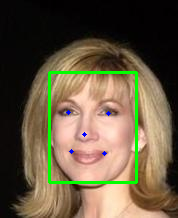

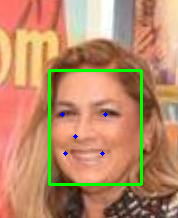

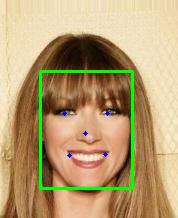

Face detection rate on 300 test images: 100.0%


In [11]:
from google.colab.patches import cv2_imshow

test_ids = partition[partition["partition"] == 2]["image_id"].sample(300, random_state=1).tolist()
found = 0
for i, iid in enumerate(test_ids):
    img = cv2.imread(os.path.join(IMG_DIR, iid))
    faces = detect_faces(img)
    found += len(faces) > 0
    if i < 3:
        cv2_imshow(draw(img, faces))
print(f"Face detection rate on {len(test_ids)} test images: {found/len(test_ids):.1%}")

In [12]:
demo_ids = partition[partition["partition"] == 0]["image_id"].head(10).tolist()
for iid in demo_ids:
    enroll(f"celeba_{iid[:-4]}", cv2.imread(os.path.join(IMG_DIR, iid)))
print("Authorized people in database:", list(face_db.keys()))

Authorized people in database: ['celeba_000001', 'celeba_000002', 'celeba_000003', 'celeba_000004', 'celeba_000005', 'celeba_000006', 'celeba_000007', 'celeba_000008', 'celeba_000009', 'celeba_000010']


In [14]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode

def take_photo(quality=0.9):
    js = Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const btn = document.createElement('button');
      btn.textContent = 'Capture';
      div.appendChild(btn);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => btn.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }""")
    display(js)
    data = eval_js("takePhoto({})".format(quality))
    return cv2.imdecode(np.frombuffer(b64decode(data.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)

def data_url_to_img(url):
    return cv2.imdecode(np.frombuffer(b64decode(url.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)

def img_to_data_url(img):
    _, buf = cv2.imencode(".png", img)
    return "data:image/png;base64," + b64encode(buf).decode()

def video_stream():
    js = Javascript(r"""
    var video, div=null, stream, captureCanvas, imgElement, labelElement, pendingResolve=null, shutdown=false;
    function removeDom() {
      stream.getVideoTracks()[0].stop(); video.remove(); div.remove();
      video=null; div=null; stream=null; imgElement=null; captureCanvas=null; labelElement=null;
    }
    function onAnimationFrame() {
      if (!shutdown) window.requestAnimationFrame(onAnimationFrame);
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8);
        }
        var lp = pendingResolve; pendingResolve = null; lp(result);
      }
    }
    async function createDom() {
      if (div !== null) return stream;
      div = document.createElement('div');
      div.style.border = '2px solid black'; div.style.padding = '3px'; div.style.width = '100%'; div.style.maxWidth = '600px';
      document.body.appendChild(div);
      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data'; labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement); div.appendChild(modelOut);
      video = document.createElement('video');
      video.style.display = 'block'; video.width = div.clientWidth - 6; video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});
      div.appendChild(video);
      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute'; imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);
      const instruction = document.createElement('div');
      instruction.innerHTML = '<span style="color: red; font-weight: bold;">Click the video to STOP</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };
      video.srcObject = stream;
      await video.play();
      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) { removeDom(); shutdown = false; return ''; }
      stream = await createDom();
      if (label != "") labelElement.innerHTML = label;
      if (imgData != "") {
        var r = video.getClientRects()[0];
        imgElement.style.top = r.top + "px"; imgElement.style.left = r.left + "px";
        imgElement.style.width = r.width + "px"; imgElement.style.height = r.height + "px";
        imgElement.src = imgData;
      }
      var result = await new Promise(function(resolve) { pendingResolve = resolve; });
      shutdown = false;
      return {'img': result};
    }""")
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

<IPython.core.display.Javascript object>

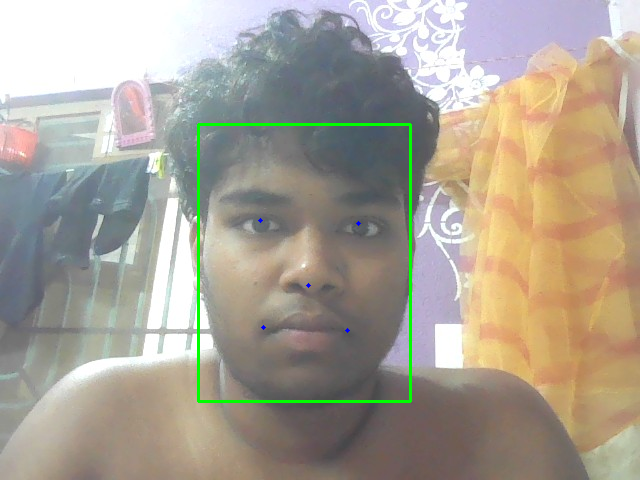

Enrolled!
Samples for YourName : 2


In [19]:
NAME = "YourName"      # <-- change this

photo = take_photo()
ok = enroll(NAME, photo)
cv2_imshow(draw(photo, detect_faces(photo)))
print("Enrolled!" if ok else "No face found - try again with better light")
print("Samples for", NAME, ":", len(face_db.get(NAME, [])))

In [20]:
import time

video_stream()
label_html, bbox_png = "Starting...", ""
t0, frames = time.time(), 0

while True:
    js_reply = video_frame(label_html, bbox_png)
    if not js_reply:
        break
    frame = data_url_to_img(js_reply["img"])
    faces = detect_faces(frame)

    overlay = np.zeros((480, 640, 4), dtype=np.uint8)
    status = "No face"
    for f in faces:
        name, score = identify(frame, f)
        granted = name != "Unknown"
        text = f"{'GRANTED' if granted else 'DENIED'}: {name} ({score:.2f})"
        color = (0, 255, 0, 255) if granted else (0, 0, 255, 255)
        x, y, w, h = f[:4].astype(int)
        cv2.rectangle(overlay, (x, y), (x + w, y + h), color, 2)
        for k in range(5):
            cv2.circle(overlay, (int(f[4 + 2*k]), int(f[5 + 2*k])), 3, (255, 0, 0, 255), -1)
        cv2.putText(overlay, text, (x, max(y - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        status = text
    overlay[:, :, 3] = (overlay.sum(axis=2) > 0) * 255
    bbox_png = img_to_data_url(overlay)

    frames += 1
    label_html = f"{status} | {frames/(time.time()-t0):.1f} FPS"

<IPython.core.display.Javascript object>

In [25]:
pip install fer

In [26]:
import cv2
import numpy as np
import time

video_stream()
label_html, bbox_png = "Starting...", ""
t0, frames = time.time(), 0

while True:
    js_reply = video_frame(label_html, bbox_png)
    if not js_reply:
        break
    frame = data_url_to_img(js_reply["img"])
    faces = detect_faces(frame)

    overlay = np.zeros((480, 640, 4), dtype=np.uint8)
    status = "No face"

    for i, f in enumerate(faces):
        name, score = identify(frame, f)
        granted = name != "Unknown"

        # Face bounding box coordinates
        x, y, w, h = f[:4].astype(int)

        # 5 Landmarks returned by YuNet:
        # Left eye (0), Right eye (1), Nose (2), Left mouth corner (3), Right mouth corner (4)
        lex, ley = f[4], f[5]
        rex, rey = f[6], f[7]
        nx, ny = f[8], f[9]
        lmx, lmy = f[10], f[11]
        rmx, rmy = f[12], f[13]

        # Heuristic calculations based on face geometry
        eye_dist = np.sqrt((lex - rex)**2 + (ley - rey)**2)
        mouth_width = np.sqrt((lmx - rmx)**2 + (lmy - rmy)**2)
        mouth_y_avg = (lmy + rmy) / 2.0

        # Vertical distance from nose to mouth
        nose_mouth_dist = mouth_y_avg - ny

        # Eye-to-mouth ratio & mouth stretch
        mouth_ratio = mouth_width / max(1.0, eye_dist)

        # Smile/Happy check: higher corners relative to mouth center line
        mouth_center_y = (lmy + rmy) / 2.0

        # Map states based on geometric ratios:
        if mouth_ratio > 0.65:
            mapped_status = "Happy"
        elif mouth_ratio < 0.45:
            mapped_status = "Sad"
        elif nose_mouth_dist / max(1.0, eye_dist) < 0.40:
            mapped_status = "Aggression"
        else:
            mapped_status = "Tension"

        text_id = f"{'GRANTED' if granted else 'DENIED'}: {name}"
        text_emo = f"State: {mapped_status}"

        color = (0, 255, 0, 255) if granted else (0, 0, 255, 255)

        cv2.rectangle(overlay, (x, y), (x + w, y + h), color, 2)
        for k in range(5):
            cv2.circle(overlay, (int(f[4 + 2*k]), int(f[5 + 2*k])), 3, (255, 0, 0, 255), -1)

        cv2.putText(overlay, text_id, (x, max(y - 25, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        cv2.putText(overlay, text_emo, (x, max(y - 5, 30)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255, 255), 2)
        status = f"{text_id} | {text_emo}"

    overlay[:, :, 3] = (overlay.sum(axis=2) > 0) * 255
    bbox_png = img_to_data_url(overlay)

    frames += 1
    label_html = f"{status} | {frames/(time.time()-t0):.1f} FPS"

<IPython.core.display.Javascript object>

In [30]:
from google.colab import files
files.download("/content/face_db.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import pickle

# Load and read your database locally
with open('face_db.pkl', 'rb') as f:
    face_db = pickle.load(f)

# Print the names of registered people
print("Registered names:", list(face_db.keys()))

Registered names: ['celeba_000001', 'celeba_000002', 'celeba_000003', 'celeba_000004', 'celeba_000005', 'celeba_000006', 'celeba_000007', 'celeba_000008', 'celeba_000009', 'celeba_000010', 'YourName']
